In [4]:
import pandas as pd
import numpy as np

In [5]:
df=pd.read_csv('water_potability.csv')
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))

In [6]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=123)

for train_indices, test_indices in splitter.split(df, df["Potability"]):
    train_set = df.iloc[train_indices]
    test_set = df.iloc[test_indices]

print("Training set:", len(train_set))
print("Testing set:", len(test_set))

print("\nTraining set distribution:")
print(train_set["Potability"].value_counts())
print(train_set.head())

print("\nTesting set distribution:")
print(test_set["Potability"].value_counts())
print(test_set.head())

Training set: 2620
Testing set: 656

Training set distribution:
Potability
0    1598
1    1022
Name: count, dtype: int64
            ph    Hardness        Solids  Chloramines     Sulfate  \
1318  6.724639  223.175415  41552.019664     7.744700  271.157120   
1979  7.201702  147.711086  37308.994159     5.677451  279.164446   
1239  6.810467  209.735559  32602.340084     7.422781  341.174269   
946   5.924540  186.620068  44376.187382     6.614180  341.637774   
1032  8.697122  166.452774  27752.000240     5.350924  372.264099   

      Conductivity  Organic_carbon  Trihalomethanes  Turbidity  Potability  
1318    463.885216       13.165035        61.058796   2.921415           0  
1979    395.976824       13.326125        63.626894   3.883250           1  
1239    340.030089       16.736749        42.349461   4.402340           0  
946     273.446838       12.758115        59.456691   4.224343           0  
1032    393.555796       13.748668        75.024545   4.180568           0  

T

For this project, I selected nine independent variables (X) that represent different water quality measurements: pH, Hardness, Solids, Chloramines, Sulfate, Conductivity, Organic Carbon, Trihalomethanes, and Turbidity.

The target variable (y) is Potability, which indicates whether water is safe to drink. A value of 1 represents potable water, while 0 represents non-potable water.

I chose these features because they describe the chemical and physical characteristics of water that could influence its potability. I decided to use all nine measurements initially rather than removing features, so I can evaluate how well they work together when predicting water potability.

Since Potability is already a binary categorical variable, there is no need to create additional buckets.

In [7]:
x_train=train_set.drop("Potability", axis=1)
y_train=train_set["Potability"]
x_test=test_set.drop("Potability", axis=1)
y_test=test_set["Potability"]

from sklearn.tree import DecisionTreeClassifier
tree_classifier = DecisionTreeClassifier(random_state=42)
tree_classifier.fit(x_train, y_train)
y_predicted = tree_classifier.predict(x_test)


from sklearn.metrics import confusion_matrix
matrix = confusion_matrix(y_test, y_predicted)
print(matrix)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print ("Accuracy is ", accuracy_score(y_test, y_predicted))

# We have to specify how to combine for the multiclassifications
print ("Precision is ", precision_score(y_test, y_predicted, average="weighted"))
print ("Sensitivity is ", recall_score(y_test, y_predicted, average="weighted"))
print ("F1 is ", f1_score(y_test, y_predicted, average="weighted"))

[[272 128]
 [120 136]]
Accuracy is  0.6219512195121951
Precision is  0.6241308053154743
Sensitivity is  0.6219512195121951
F1 is  0.622949949779218


The Decision Tree model achieved an accuracy of 62.20%, precision of 62.41%, sensitivity of 62.20%, and an F1-score of 62.29%.
Based on the confusion matrix, the model correctly predicted 272 non-potable water samples and 136 potable water samples. Overall, the model performed okay, it could perform better.

In [8]:
from sklearn.svm import SVC
svm_classifier = SVC()
svm_classifier.fit(x_train, y_train)

#Evaluating the model
from sklearn.metrics import confusion_matrix
y_pred = svm_classifier.predict(x_test)
matrix= confusion_matrix(y_test, y_pred)
print(matrix)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print ("Accuracy is ", accuracy_score(y_test, y_pred))
print("Precision is ", precision_score(y_test, y_pred, average="weighted"))
print ("Sensitivity is ", recall_score(y_test, y_pred, average="weighted"))
print ("F1 is ", f1_score(y_test, y_pred, average="weighted"))
print("Support:")

print(svm_classifier.support_)
print(svm_classifier.support_vectors_)
print(svm_classifier.n_support_)


[[400   0]
 [256   0]]
Accuracy is  0.6097560975609756
Precision is  0.37180249851279
Sensitivity is  0.6097560975609756
F1 is  0.4619364375461936
Support:
[   0    2    3 ... 2613 2614 2616]
[[6.72463934e+00 2.23175415e+02 4.15520197e+04 ... 1.31650346e+01
  6.10587957e+01 2.92141477e+00]
 [6.81046652e+00 2.09735559e+02 3.26023401e+04 ... 1.67367486e+01
  4.23494608e+01 4.40233951e+00]
 [5.92454048e+00 1.86620068e+02 4.43761874e+04 ... 1.27581153e+01
  5.94566909e+01 4.22434251e+00]
 ...
 [7.65754173e+00 2.30820008e+02 3.50562322e+04 ... 1.84813964e+01
  7.22050747e+01 4.79252745e+00]
 [6.27746309e+00 2.25941935e+02 2.28073389e+04 ... 1.32256659e+01
  5.08033529e+01 3.12316616e+00]
 [7.03675210e+00 1.68409525e+02 2.61485379e+04 ... 1.06745825e+01
  5.18769548e+01 3.89332683e+00]]
[1078 1022]


C:\Users\s567783\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


 The SVM model achieved an accuracy of 61%, a precision of 37.18%, a sensitivity of 60.98%, and an F1 score of 46.19%. Looking at the confusion matrix, the model predicted every observation as class 0. It correctly classified 400 observations but failed to identify any of the 256 observations in class 1. The model also had 1078 support vectors for class 0 and 1022 for class 1. Overall, I learned that accuracy alone does not tell us how well a model performs, since the SVM had 61% accuracy but failed to predict any class 1 observations.

The Decision Tree performed slightly better than the SVM model. It achieved an accuracy of 62.2% compared to 61% for SVM, and a precision of 62.41% compared to 37.18%. Based on these results, the Decision Tree was the better performing model for this dataset. 

In [9]:
from sklearn.cluster import KMeans
kmeans_classifier = KMeans(n_clusters=2, random_state=42)
kmeans_classifier.fit(x_train)

import math
print("The distortation is: ", kmeans_classifier.inertia_)
RMS_average = math.sqrt(kmeans_classifier.inertia_/len(x_train))
print("The RMS average is: ", RMS_average)

print("The centroids are:", kmeans_classifier.cluster_centers_)
print("Assignments are: ", kmeans_classifier.labels_)

two_classifier = KMeans(n_clusters=2, n_init="auto")
two_classifier.fit(x_train)
two_RMS_average = math.sqrt(two_classifier.inertia_/len(x_train))

three_classifier = KMeans(n_clusters=3, n_init="auto")
three_classifier.fit(x_train)
three_RMS_average = math.sqrt(three_classifier.inertia_/len(x_train))

print("The distortion for 2 clusters is: ", two_classifier.inertia_, "and the RMS average is: ", two_RMS_average)
print("The distortion for 3 clusters is: ", three_classifier.inertia_, "and the RMS average is: ", three_RMS_average)


The distortation is:  72313487003.30348
The RMS average is:  5253.62423080608
The centroids are: [[7.15813108e+00 1.97103787e+02 1.64387821e+04 7.18483081e+00
  3.35785129e+02 4.22934485e+02 1.43036041e+01 6.63599912e+01
  3.96852817e+00]
 [6.98161089e+00 1.94561299e+02 3.09963537e+04 7.03917643e+00
  3.29208216e+02 4.30419575e+02 1.44261660e+01 6.60401381e+01
  3.97844705e+00]]
Assignments are:  [1 1 1 ... 0 0 0]
The distortion for 2 clusters is:  72313487003.30348 and the RMS average is:  5253.62423080608
The distortion for 3 clusters is:  37897495193.77254 and the RMS average is:  3803.247667724334


K-Means was used to group the water samples into two and three clusters. When increasing the number of clusters from two to three, the distortion decreased from approximately 72.3 billion to 37.9 billion. The cluster centroids showed that Solids had the biggest difference between the groups, while the other features were relatively similar.


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\s567783\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


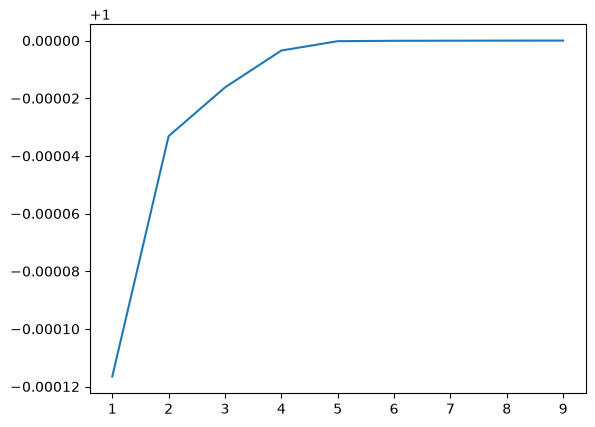

In [10]:
from sklearn.decomposition import PCA
pca=PCA()
pca.fit(x_train)
cumulative_sums=np.cumsum(pca.explained_variance_ratio_)
!pip install matplotlib
import matplotlib.pyplot as plt
d_values=[i+1 for i in range(len(cumulative_sums))]
plt.plot(d_values, cumulative_sums)
plt.show()

In [11]:
print(pca.explained_variance_ratio_)

[9.99883440e-01 8.34156098e-05 1.69036015e-05 1.27951003e-05
 3.23516524e-06 1.43373950e-07 3.21899924e-08 2.70159575e-08
 7.83065938e-09]


The first principal component explained approximately 99.99% of the variance, while the remaining components contributed very little. This suggests that most of the variation in the dataset is captured by the first component.

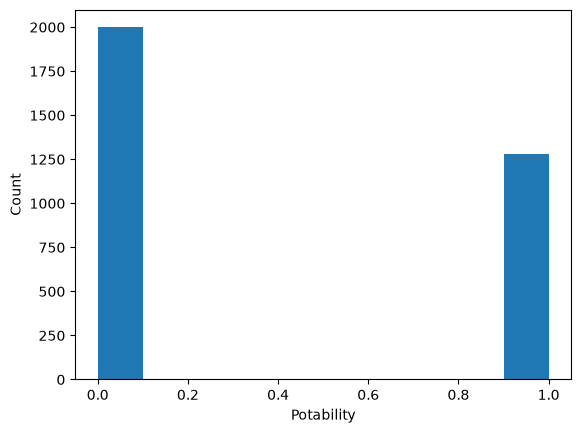

In [12]:
plt.hist(df["Potability"])
plt.xlabel("Potability")
plt.ylabel("Count")
plt.show()

The analysis of the water potability dataset revealed some interesting patterns in the water quality measurements. PCA showed that the first principal component explained approximately 99.99% of the variance. However, this result may be influenced by differences in some features scales, especially Solids.

K-Means clustering grouped the water samples into two and three clusters. The results showed that Solids had the largest difference between cluster centroids, suggesting that this feature strongly influenced how the samples were grouped. However, the clusters do not necessarily represent potable and non-potable water.

The classification results also provided insight into the dataset's predictive potential. The Decision Tree achieved an accuracy of approximately 62%, while the SVM achieved approximately 61%. However, the SVM predicted every sample as non-potable, showing that accuracy alone does not always reflect a model's ability to identify both classes.

Overall, the results suggest that predicting water potability is challenging using the available features. Although the dataset contains useful water quality measurements, the models struggled to distinguish between potable and non-potable samples. In a real-world application, improving feature processing and model performance could help identify potentially unsafe water samples more reliably.

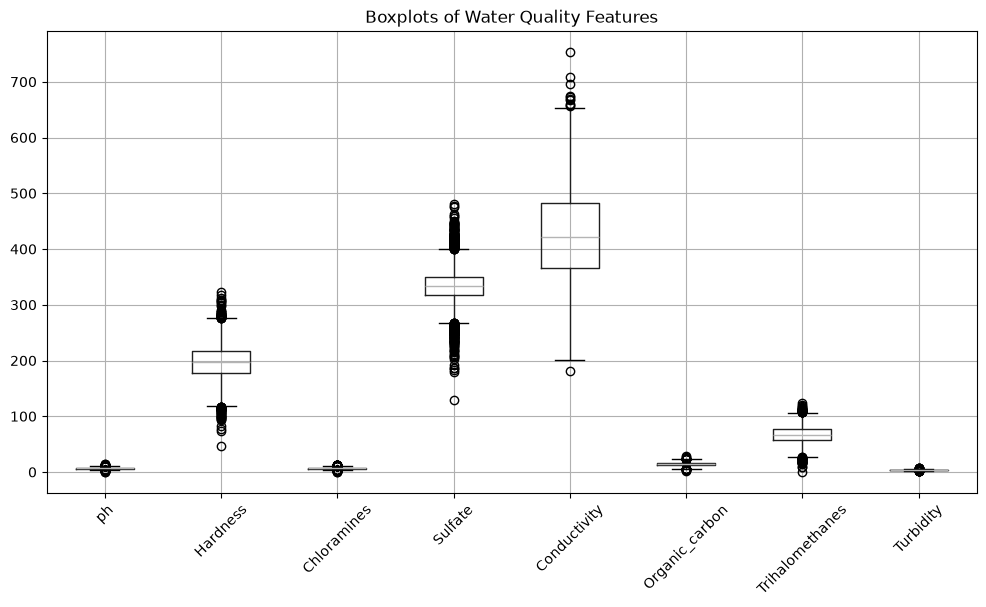

In [17]:
df.drop(columns=["Solids", "Potability"]).boxplot(figsize=(12,6))
plt.xticks(rotation=45)
plt.title("Boxplots of Water Quality Features")
plt.show()

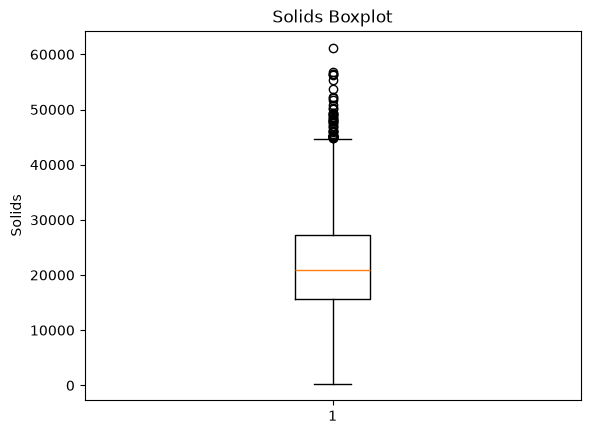

In [18]:
plt.boxplot(df["Solids"])
plt.title("Solids Boxplot")
plt.ylabel("Solids")
plt.show()

I used boxplots to identify potential anomalous data in the dataset. Several features, including Hardness, Sulfate, Conductivity and Trihalomethanes, contain values outside the whiskers. Solids also has several unusually high values. These outliers may represent unusual water characteristics or naturally occurring variations in the samples.

The boxplots show that the dataset contains potential anomalous values across several water quality features. This indicates that water samples have varying characteristics, with some measurements being significantly higher or lower than most others. These variations may be useful when predicting water potability because unusual measurements could influence whether a sample is classified as potable or non-potable. Therefore, the outliers were kept for further analysis rather than automatically removed.

In [13]:
!pip install tensorflow
import tensorflow as tf
from tensorflow.keras import layers


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\s567783\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [14]:
n_hidden1 = 32
n_hidden2 = 16
n_outputs = 2

model = tf.keras.Sequential()
model.add(layers.Dense(n_hidden1, activation='relu'))
model.add(layers.Dense(n_hidden2, activation='relu'))
model.add(layers.Dense(n_outputs, activation='softmax'))
model.compile(optimizer=
              tf.keras.optimizers.SGD(learning_rate=0.3, momentum=0.01),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

from tensorflow.keras.utils import to_categorical

y_train_nn = to_categorical(y_train)
y_test_nn = to_categorical(y_test)

x_train_nn = x_train.astype('float32')
x_test_nn = x_test.astype('float32')

x_train_nn = x_train.astype('float32')
x_train_nn = x_train_nn / x_train.max()

x_test_nn = x_test.astype('float32')
x_test_nn = x_test.astype('float32') / x_train.max()

model.fit(x_train_nn, y_train_nn, epochs=5, batch_size=10)
model.evaluate(x_test_nn, y_test_nn, batch_size=32)

y_predicted = model.predict(x_test_nn)

y_predicted = np.argmax(y_predicted, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predicted))

print("Accuracy:", accuracy_score(y_test, y_predicted))
print("Precision:", precision_score(y_test, y_predicted, average="weighted"))
print("Sensitivity:", recall_score(y_test, y_predicted, average="weighted"))
print("F1 Score:", f1_score(y_test, y_predicted, average="weighted"))

Epoch 1/5
262/262 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.6095 - loss: 0.6753
Epoch 2/5
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6095 - loss: 0.6725
Epoch 3/5
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6084 - loss: 0.6713
Epoch 4/5
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6050 - loss: 0.6723  
Epoch 5/5
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6073 - loss: 0.6717
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6098 - loss: 0.6668  
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Confusion Matrix:
[[400   0]
 [256   0]]
Accuracy: 0.6097560975609756
Precision: 0.37180249851279
Sensitivity: 0.6097560975609756
F1 Score: 0.4619364375461936


C:\Users\s567783\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


The Neural Network achieved 60.98% accuracy after 5 epochs. However, the confusion matrix showed that it predicted every sample as class 0 and failed to identify any class 1 samples. This resulted in a low F1 score of 46.19%. Although neural networks are powerful classification tools, this model did not perform well on our dataset.We might need to scale the feautres.

In [20]:
from sklearn.ensemble import RandomForestClassifier
forest_classifier = RandomForestClassifier(random_state=42)
forest_classifier.fit(x_train, y_train)

y_predicted = forest_classifier.predict(x_test)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predicted))

print("Accuracy:", accuracy_score(y_test, y_predicted))
print("Precision:", precision_score(y_test, y_predicted, average="weighted"))
print("Sensitivity:", recall_score(y_test, y_predicted, average="weighted"))
print("F1 Score:", f1_score(y_test, y_predicted, average="weighted"))

Confusion Matrix:
[[341  59]
 [170  86]]
Accuracy: 0.6509146341463414
Precision: 0.6383568227341629
Sensitivity: 0.6509146341463414
F1 Score: 0.6238668275363904


Random Forest performed better than the other models, achieving 65.09% accuracy and a 62.39% F1 score. It also successfully identified samples from both classes, unlike the SVM and Neural Network, which predicted only class 0. However, it still incorrectly classified 170 potable samples as non-potable and 59 non-potable samples as potable. This shows that predicting water potability remains challenging with the current features and model settings